Starting device collision analysis...
Processing device: AveirVR, initial length: 38
Processing device: AveirVR, length: 15
Processing /data_fast/Work/MS_HF_cohort/images/AveirVR/RV_Collision//csv/2_L15.csv
  -> Loaded 5940 data points
Processing /data_fast/Work/MS_HF_cohort/images/AveirVR/RV_Collision//csv/3_L15.csv
  -> Loaded 5940 data points
Processing /data_fast/Work/MS_HF_cohort/images/AveirVR/RV_Collision//csv/8_L15.csv
  -> Loaded 6120 data points
Processing /data_fast/Work/MS_HF_cohort/images/AveirVR/RV_Collision//csv/9_L15.csv
  -> Loaded 6120 data points
Processing /data_fast/Work/MS_HF_cohort/images/AveirVR/RV_Collision//csv/14_L15.csv
  -> Loaded 8844 data points
Processing device: AveirVR, length: 20
Processing /data_fast/Work/MS_HF_cohort/images/AveirVR/RV_Collision//csv/2_L20.csv
  -> Loaded 5940 data points
Processing /data_fast/Work/MS_HF_cohort/images/AveirVR/RV_Collision//csv/3_L20.csv
  -> Loaded 5940 data points
Processing /data_fast/Work/MS_HF_cohort/images/Aveir

/home/alee9/anaconda3/envs/py_vista/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)


             Mixed Linear Model Regression Results
Model:              MixedLM  Dependent Variable: collision_value
No. Observations:   692244   Method:             REML           
No. Groups:         5        Scale:              4.4658         
Min. group size:    124740   Log-Likelihood:     -1500265.1468  
Max. group size:    185724   Converged:          Yes            
Mean group size:    138448.8                                    
----------------------------------------------------------------
                     Coef.  Std.Err.    z    P>|z| [0.025 0.975]
----------------------------------------------------------------
Intercept             1.879    0.945   1.989 0.047  0.027  3.732
C(device)[T.AveirVR]  0.016    0.006   2.540 0.011  0.004  0.028
C(device)[T.Micra]   -0.028    0.006  -4.507 0.000 -0.040 -0.016
C(length)[T.20]       0.755    0.010  79.396 0.000  0.736  0.773
C(length)[T.25]       1.497    0.010 157.539 0.000  1.479  1.516
C(length)[T.30]       2.456    0.010 25

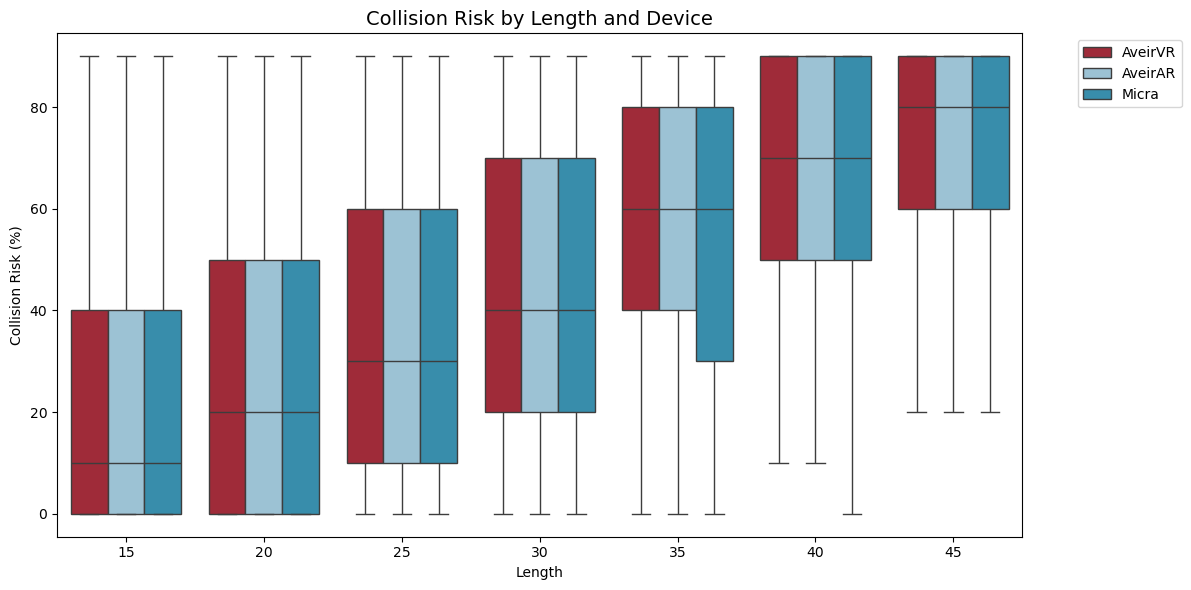

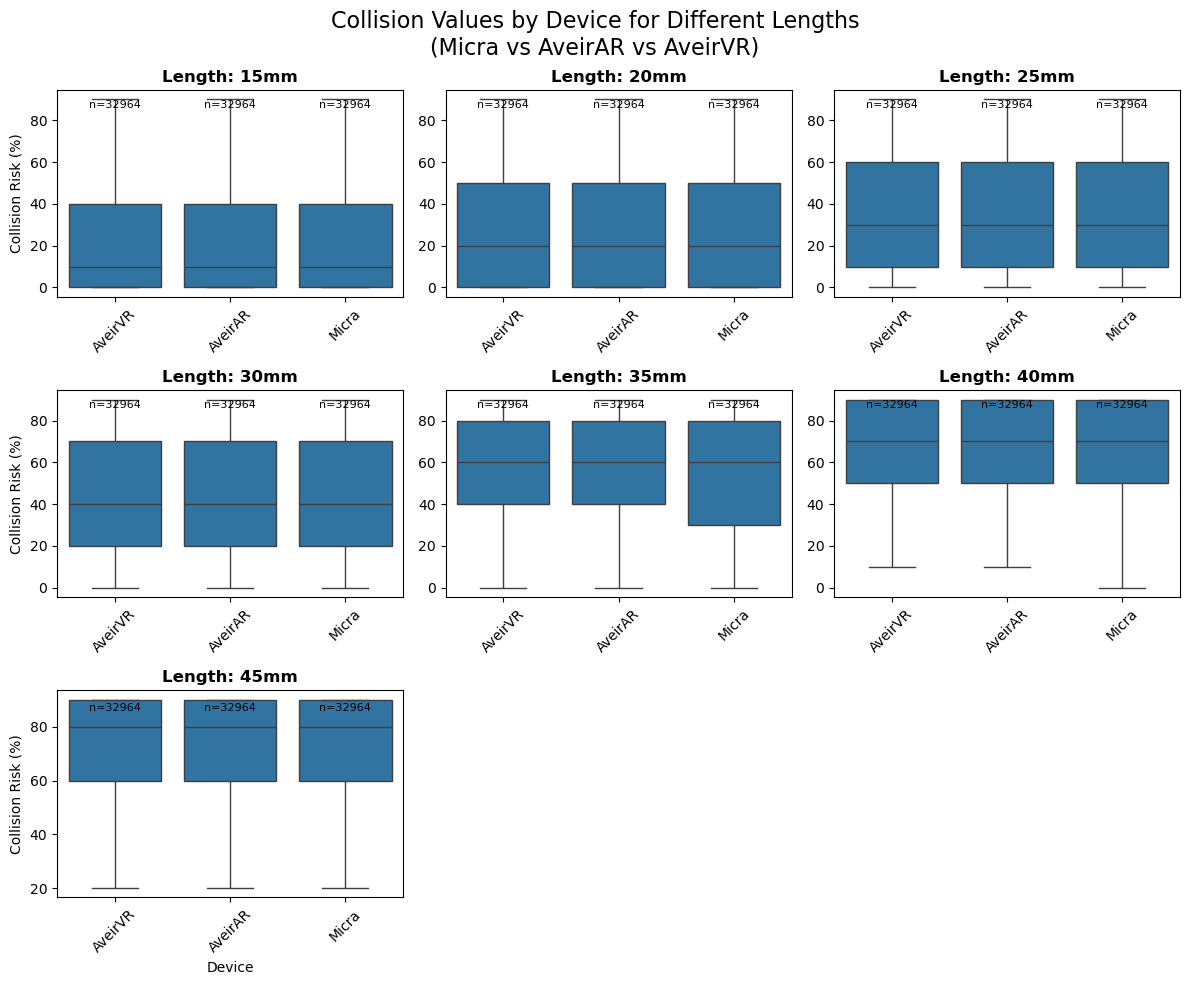


Statistical Summary by Length and Device:

Length: 15
         count    mean     std  min   max  median
device                                           
AveirAR  32964  20.459  22.889  0.0  90.0    10.0
AveirVR  32964  20.228  22.173  0.0  90.0    10.0
Micra    32964  20.064  23.148  0.0  90.0    10.0

Length: 20
         count    mean     std  min   max  median
device                                           
AveirAR  32964  27.846  27.134  0.0  90.0    20.0
AveirVR  32964  27.824  26.880  0.0  90.0    20.0
Micra    32964  27.718  27.486  0.0  90.0    20.0

Length: 25
         count    mean     std  min   max  median
device                                           
AveirAR  32964  35.178  28.728  0.0  90.0    30.0
AveirVR  32964  35.761  28.469  0.0  90.0    30.0
Micra    32964  34.728  28.810  0.0  90.0    30.0

Length: 30
         count    mean     std  min   max  median
device                                           
AveirAR  32964  44.734  28.054  0.0  90.0    40.0
AveirVR  

In [23]:
# Statistical analysis of the csv files 
import pandas as pd
import numpy as np
import os
import csv
from scipy import stats
from itertools import combinations
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

def collect_collision_data(collision_field, lengths=[None, 15, 20, 25, 30, 35, 40, 45]):
    """
    Collect collision data for all devices and AHA regions into a DataFrame.
    
    Parameters:
    -----------
    collision_field : str
        The collision field type
    length : float or str
        The length parameter for file naming
    
    Returns:
    --------
    df : pandas.DataFrame
        DataFrame with columns: device, AHA_region, theta, z, collision_value, init_len
    """
    
    # Initialize list to store all data
    all_data = []
    
    # Device specifications
    device_specs = {
        'AveirVR': 38,
        'AveirAR': 32.2,
        'Micra': 25.9
    }
    
    for device in ['AveirVR', 'AveirAR', 'Micra']:
        # Get initial length for this device
        init_len = device_specs.get(device)
        print(f'Processing device: {device}, initial length: {init_len}')
        if init_len is None:
            print(f'WARNING - DEVICE: {device} is not AveirVR, AveirAR or Micra')
            continue
            
        # Set output path
        if collision_field == 'Combined_Collision':
            images_outpath = f'/data_fast/Work/MS_HF_cohort/images/{device}/'
        else:
            images_outpath = f'/data_fast/Work/MS_HF_cohort/images/{device}/{collision_field}/'
        
        for length_input in lengths:
            if length_input is None: 
                length = init_len
            else:
                length = length_input
            print(f'Processing device: {device}, length: {length}')
            # Process each AHA region
            for AHA_region in [2, 3, 8, 9, 14]:
                csv_region_outfile = f'{images_outpath}/csv/{AHA_region}_L{length}.csv'
                print(f'Processing {csv_region_outfile}')
                
                if os.path.exists(csv_region_outfile):
                    try:
                        with open(csv_region_outfile, 'r') as csvfile:
                            reader = csv.reader(csvfile)
                            header = next(reader)
                            data = [row for row in reader]
                        
                        # Convert to numpy array
                        data = np.array(data, dtype=float)
                        
                        if len(data) > 0:
                            # Extract values
                            theta = data[:, 0]
                            z = data[:, 1]
                            collision_values = data[:, 2]
                            
                            # Add to collection
                            for i in range(len(collision_values)):
                                all_data.append({
                                    'device': device,
                                    'AHA_region': AHA_region,
                                    'theta': theta[i],
                                    'z': z[i],
                                    'collision_value': collision_values[i],
                                    'length': length
                                })
                            
                            print(f'  -> Loaded {len(collision_values)} data points')
                        else:
                            print(f'  -> No data found in file')
                            
                    except Exception as e:
                        print(f'  -> Error reading file: {e}')
                else:
                    print(f'  -> File not found')
        
    # Convert to DataFrame
    df = pd.DataFrame(all_data)
    print(f'\nTotal data points collected: {len(df)}')
    print(f'Devices: {df["device"].unique()}')
    print(f'AHA regions: {sorted(df["AHA_region"].unique())}')
    
    return df

def analyze_device_differences(df):
    """
    Perform statistical analysis comparing collision values between devices,
    including ANOVA, pairwise t-tests, and a mixed-effects model.
    
    Parameters:
    -----------
    df : pandas.DataFrame
        DataFrame with 'device', 'collision_value', and 'AHA_region' columns.
    
    Returns:
    --------
    results : dict
        Dictionary containing statistical test results
    """
    
    results = {}

    print("\n" + "="*60)
    print("OVERALL ANALYSIS (All AHA Regions Combined)")
    print("="*60)
    
    # Summary statistics by device
    summary_stats = df.groupby('device')['collision_value'].agg([
        'count', 'mean', 'std', 'median', 'min', 'max'
    ]).round(4)
    print("\nSummary Statistics by Device:")
    print(summary_stats)
    
    # Overall ANOVA and pairwise t-tests
    devices = df['device'].unique()
    device_groups = [df[df['device'] == device]['collision_value'].values for device in devices]
    
    f_stat, p_anova = stats.f_oneway(*device_groups)
    results['overall'] = {
        'anova': {'f_stat': f_stat, 'p_value': p_anova},
        'pairwise': {},
        'mixed_effects': {}
    }

    print(f"\nANOVA Test:")
    print(f"F-statistic: {f_stat:.4f}")
    print(f"p-value: {p_anova:.6f}")
    print(f"Significant difference: {'Yes' if p_anova < 0.05 else 'No'}")

    # Pairwise t-tests
    print(f"\nPairwise t-tests (overall):")
    for device1, device2 in combinations(devices, 2):
        group1 = df[df['device'] == device1]['collision_value'].values
        group2 = df[df['device'] == device2]['collision_value'].values
        
        t_stat, p_val = stats.ttest_ind(group1, group2)
        results['overall']['pairwise'][f'{device1}_vs_{device2}'] = {
            't_stat': t_stat, 'p_value': p_val
        }
        
        print(f"  {device1} vs {device2}: t={t_stat:.4f}, p={p_val:.6f} {'*' if p_val < 0.05 else ''}")

    # Mixed Effects Model
    print(f"\nMixed Effects Model (device = fixed, region = random):")
    try:
        model = smf.mixedlm("collision_value ~ device", df, groups=df["AHA_region"])
        mixed_result = model.fit()
        print(mixed_result.summary())
        
        results['overall']['mixed_effects']['summary'] = mixed_result.summary().as_text()
        results['overall']['mixed_effects']['pvalues'] = mixed_result.pvalues.to_dict()
    except Exception as e:
        print(f"  Error fitting mixed effects model: {e}")
        results['overall']['mixed_effects']['error'] = str(e)

    # Analysis by AHA Region
    print("\n" + "="*60)
    print("ANALYSIS BY AHA REGION")
    print("="*60)
    
    results['by_region'] = {}
    
    for region in sorted(df['AHA_region'].unique()):
        print(f"\nAHA Region {region}:")
        region_data = df[df['AHA_region'] == region]
        
        if len(region_data) == 0:
            print("  No data available")
            continue
        
        # Summary stats
        region_stats = region_data.groupby('device')['collision_value'].agg([
            'count', 'mean', 'std'
        ]).round(4)
        print(region_stats)
        
        # Regional ANOVA
        region_groups = [region_data[region_data['device'] == device]['collision_value'].values 
                         for device in devices]
        
        non_empty_groups = [g for g in region_groups if len(g) > 0]
        if len(non_empty_groups) < 2:
            print("  Insufficient data for comparison")
            continue

        f_stat_region, p_anova_region = stats.f_oneway(*non_empty_groups)
        results['by_region'][region] = {
            'anova': {'f_stat': f_stat_region, 'p_value': p_anova_region},
            'pairwise': {}
        }
        
        print(f"  ANOVA: F={f_stat_region:.4f}, p={p_anova_region:.6f} {'*' if p_anova_region < 0.05 else ''}")
        
        # Pairwise t-tests
        available_devices = region_data['device'].unique()
        if len(available_devices) >= 2:
            print(f"  Pairwise comparisons:")
            for device1, device2 in combinations(available_devices, 2):
                group1 = region_data[region_data['device'] == device1]['collision_value'].values
                group2 = region_data[region_data['device'] == device2]['collision_value'].values
                
                if len(group1) > 0 and len(group2) > 0:
                    t_stat, p_val = stats.ttest_ind(group1, group2)
                    results['by_region'][region]['pairwise'][f'{device1}_vs_{device2}'] = {
                        't_stat': t_stat, 'p_value': p_val
                    }
                    
                    print(f"    {device1} vs {device2}: t={t_stat:.4f}, p={p_val:.6f} {'*' if p_val < 0.05 else ''}")
    
    return results

def analyse_length_difference(df, device='Micra'):
    """
    Perform statistical analysis comparing collision values between devices.
    
    Parameters:
    -----------
    df : pandas.DataFrame
        DataFrame with collision data
    
    Returns:
    --------
    results : dict
        Dictionary containing statistical test results
    """
    
    results = {}
    
    # Overall comparison (all regions combined)
    print("\n" + "="*60)
    print("OVERALL ANALYSIS (All AHA Regions Combined)")
    print("="*60)
    df=df[df['device']==device]
    # Summary statistics by device
    summary_stats = df.groupby('length')['collision_value'].agg([
        'count', 'mean', 'std', 'median', 'min', 'max'
    ]).round(4)
    print("\nSummary Statistics by Length:")
    print(summary_stats)

    # Overall ANOVA
    lengths = df['length'].unique()
    length_groups = [df[df['length'] == length]['collision_value'].values for length in lengths]
    f_stat, p_anova = stats.f_oneway(*length_groups)
    results['overall'] = {
        'anova': {'f_stat': f_stat, 'p_value': p_anova},
        'pairwise': {},
        'mixed_effects': {}
    }   

    print(f"\nANOVA Test:")
    print(f"F-statistic: {f_stat:.4f}")
    print(f"p-value: {p_anova:.6f}")
    print(f"Significant difference: {'Yes' if p_anova < 0.05 else 'No'}")       
    # Pairwise t-tests
    print(f"\nPairwise t-tests (overall):")
    for length1, length2 in combinations(lengths, 2):   
        group1 = df[df['length'] == length1]['collision_value'].values
        group2 = df[df['length'] == length2]['collision_value'].values
        
        t_stat, p_val = stats.ttest_ind(group1, group2)
        results['overall']['pairwise'][f'{length1}_vs_{length2}'] = {
            't_stat': t_stat, 'p_value': p_val
        }
        
        print(f"  {length1} vs {length2}: t={t_stat:.4f}, p={p_val:.6f} {'*' if p_val < 0.05 else ''}") 
    # Mixed Effects Model
    print(f"\nMixed Effects Model (length = fixed, region = random):")
    try:        
        model = smf.mixedlm("collision_value ~ length", df, groups=df["AHA_region"])
        mixed_result = model.fit()
        print(mixed_result.summary())
        
        results['overall']['mixed_effects']['summary'] = mixed_result.summary().as_text()
        results['overall']['mixed_effects']['pvalues'] = mixed_result.pvalues.to_dict()
    except Exception as e:
        print(f"  Error fitting mixed effects model: {e}")
        results['overall']['mixed_effects']['error'] = str(e)   

    # Analysis by AHA Region
    print("\n" + "="*60)
    print("ANALYSIS BY AHA REGION")
    print("="*60)           

    results['by_region'] = {}
    for region in sorted(df['AHA_region'].unique()):
        print(f"\nAHA Region {region}:")
        region_data = df[df['AHA_region'] == region]
        
        if len(region_data) == 0:
            print("  No data available")
            continue
        
        # Summary stats
        region_stats = region_data.groupby('length')['collision_value'].agg([
            'count', 'mean', 'std'
        ]).round(4)
        print(region_stats)
        
        # Regional ANOVA
        region_groups = [region_data[region_data['length'] == length]['collision_value'].values 
                         for length in lengths]
        
        non_empty_groups = [g for g in region_groups if len(g) > 0]
        if len(non_empty_groups) < 2:
            print("  Insufficient data for comparison")
            continue

        f_stat_region, p_anova_region = stats.f_oneway(*non_empty_groups)
        results['by_region'][region] = {
            'anova': {'f_stat': f_stat_region, 'p_value': p_anova_region},
            'pairwise': {}
        }
        
        print(f"  ANOVA: F={f_stat_region:.4f}, p={p_anova_region:.6f} {'*' if p_anova_region < 0.05 else ''}")
        
        # Pairwise t-tests
        available_lengths = region_data['length'].unique()
        if len(available_lengths) >= 2:
            print(f"  Pairwise comparisons:")
            for length1, length2 in combinations(available_lengths, 2):
                group1 = region_data[region_data['length'] == length1]['collision_value'].values
                group2 = region_data[region_data['length'] == length2]['collision_value'].values
                
                if len(group1) > 0 and len(group2) > 0:
                    t_stat, p_val = stats.ttest_ind(group1, group2)
                    results['by_region'][region]['pairwise'][f'{length1}_vs_{length2}'] = {
                        't_stat': t_stat, 'p_value': p_val
                    }
                    
                    print(f"    {length1} vs {length2}: t={t_stat:.4f}, p={p_val:.6f} {'*' if p_val < 0.05 else ''}")   

                    
    return results

def analyse_device_length_difference(df, devices=['Micra', 'AveirAR', 'AveirVR'], lengths=list(range(15, 50, 5))):
    """
    Perform statistical analysis comparing collision values between devices and lengths.
    
    Parameters:
    -----------
    df : pandas.DataFrame
        DataFrame with collision data
    devices : list
        List of devices to compare (default: ['Micra', 'AveirAR', 'AveirVR'])
    lengths : list
        List of lengths to compare (default: [15, 20, 25, 30, 35, 40, 45])
    
    Returns:
    --------
    results : dict
        Dictionary containing statistical test results
    """
    
    results = {}
    
    # Filter data for specified devices and lengths
    df_filtered = df[(df['device'].isin(devices)) & (df['length'].isin(lengths))]
    
    print(f"Analysis for devices: {devices}")
    print(f"Analysis for lengths: {lengths}")
    print(f"Total data points: {len(df_filtered)}")
    
    # Overall comparison (all regions combined)
    print("\n" + "="*80)
    print("OVERALL ANALYSIS (All AHA Regions Combined)")
    print("="*80)
    
    # Summary statistics by device and length
    summary_stats = df_filtered.groupby(['device', 'length'])['collision_value'].agg([
        'count', 'mean', 'std', 'median', 'min', 'max'
    ]).round(4)
    print("\nSummary Statistics by Device and Length:")
    print(summary_stats)
    
    # Summary statistics by device only
    device_stats = df_filtered.groupby('device')['collision_value'].agg([
        'count', 'mean', 'std', 'median', 'min', 'max'
    ]).round(4)
    print("\nSummary Statistics by Device:")
    print(device_stats)
    
    # Summary statistics by length only
    length_stats = df_filtered.groupby('length')['collision_value'].agg([
        'count', 'mean', 'std', 'median', 'min', 'max'
    ]).round(4)
    print("\nSummary Statistics by Length:")
    print(length_stats)

    # Two-way ANOVA (device × length)
    print(f"\nTwo-way ANOVA (Device × Length):")
    try:
        import statsmodels.api as sm
        from statsmodels.formula.api import ols
        
        # Two-way ANOVA
        model = ols('collision_value ~ C(device) + C(length) + C(device):C(length)', 
                   data=df_filtered).fit()
        anova_table = sm.stats.anova_lm(model, typ=2)
        print(anova_table)
        
        results['overall'] = {
            'two_way_anova': anova_table.to_dict(),
            'device_comparisons': {},
            'length_comparisons': {},
            'device_length_combinations': {},
            'mixed_effects': {}
        }
    except Exception as e:
        print(f"  Error fitting two-way ANOVA: {e}")
        results['overall'] = {'error': str(e)}

    # Device comparisons (across all lengths)
    print(f"\nDevice Comparisons (across all lengths):")
    device_groups = [df_filtered[df_filtered['device'] == device]['collision_value'].values 
                    for device in devices]
    
    # ANOVA for devices
    f_stat_device, p_anova_device = stats.f_oneway(*device_groups)
    print(f"ANOVA F-statistic: {f_stat_device:.4f}")
    print(f"ANOVA p-value: {p_anova_device:.6f}")
    print(f"Significant difference: {'Yes' if p_anova_device < 0.05 else 'No'}")
    
    # Pairwise t-tests between devices
    print(f"\nPairwise t-tests between devices:")
    for device1, device2 in combinations(devices, 2):
        group1 = df_filtered[df_filtered['device'] == device1]['collision_value'].values
        group2 = df_filtered[df_filtered['device'] == device2]['collision_value'].values
        
        if len(group1) > 0 and len(group2) > 0:
            t_stat, p_val = stats.ttest_ind(group1, group2)
            results['overall']['device_comparisons'][f'{device1}_vs_{device2}'] = {
                't_stat': t_stat, 'p_value': p_val
            }
            
            print(f"  {device1} vs {device2}: t={t_stat:.4f}, p={p_val:.6f} {'*' if p_val < 0.05 else ''}")

    # Length comparisons (across all devices)
    print(f"\nLength Comparisons (across all devices):")
    length_groups = [df_filtered[df_filtered['length'] == length]['collision_value'].values 
                    for length in lengths]
    
    # ANOVA for lengths
    f_stat_length, p_anova_length = stats.f_oneway(*length_groups)
    print(f"ANOVA F-statistic: {f_stat_length:.4f}")
    print(f"ANOVA p-value: {p_anova_length:.6f}")
    print(f"Significant difference: {'Yes' if p_anova_length < 0.05 else 'No'}")
    
    # Pairwise t-tests between lengths
    print(f"\nPairwise t-tests between lengths:")
    for length1, length2 in combinations(lengths, 2):
        group1 = df_filtered[df_filtered['length'] == length1]['collision_value'].values
        group2 = df_filtered[df_filtered['length'] == length2]['collision_value'].values
        
        if len(group1) > 0 and len(group2) > 0:
            t_stat, p_val = stats.ttest_ind(group1, group2)
            results['overall']['length_comparisons'][f'{length1}_vs_{length2}'] = {
                't_stat': t_stat, 'p_value': p_val
            }
            
            print(f"  {length1} vs {length2}: t={t_stat:.4f}, p={p_val:.6f} {'*' if p_val < 0.05 else ''}")

    # Mixed Effects Model
    print(f"\nMixed Effects Model (device + length = fixed, region = random):")
    try:
        model = smf.mixedlm("collision_value ~ C(device) + C(length)", 
                           df_filtered, groups=df_filtered["AHA_region"])
        mixed_result = model.fit()
        print(mixed_result.summary())
        
        results['overall']['mixed_effects']['summary'] = mixed_result.summary().as_text()
        results['overall']['mixed_effects']['pvalues'] = mixed_result.pvalues.to_dict()
    except Exception as e:
        print(f"  Error fitting mixed effects model: {e}")
        results['overall']['mixed_effects']['error'] = str(e)

    # Analysis by Device (comparing lengths within each device)
    print("\n" + "="*80)
    print("ANALYSIS BY DEVICE (comparing lengths within each device)")
    print("="*80)
    
    results['by_device'] = {}
    for device in devices:
        print(f"\nDevice: {device}")
        device_data = df_filtered[df_filtered['device'] == device]
        
        if len(device_data) == 0:
            print("  No data available")
            continue
        
        # Summary stats for this device
        device_length_stats = device_data.groupby('length')['collision_value'].agg([
            'count', 'mean', 'std', 'median'
        ]).round(4)
        print(device_length_stats)
        
        # ANOVA for lengths within this device
        device_length_groups = [device_data[device_data['length'] == length]['collision_value'].values 
                               for length in lengths]
        non_empty_groups = [g for g in device_length_groups if len(g) > 0]
        
        if len(non_empty_groups) < 2:
            print("  Insufficient data for comparison")
            continue
        
        f_stat_device_length, p_anova_device_length = stats.f_oneway(*non_empty_groups)
        results['by_device'][device] = {
            'anova': {'f_stat': f_stat_device_length, 'p_value': p_anova_device_length},
            'pairwise': {}
        }
        
        print(f"  ANOVA: F={f_stat_device_length:.4f}, p={p_anova_device_length:.6f} {'*' if p_anova_device_length < 0.05 else ''}")
        
        # Pairwise comparisons for lengths within this device
        available_lengths = device_data['length'].unique()
        if len(available_lengths) >= 2:
            print(f"  Pairwise length comparisons:")
            for length1, length2 in combinations(available_lengths, 2):
                group1 = device_data[device_data['length'] == length1]['collision_value'].values
                group2 = device_data[device_data['length'] == length2]['collision_value'].values
                
                if len(group1) > 0 and len(group2) > 0:
                    t_stat, p_val = stats.ttest_ind(group1, group2)
                    results['by_device'][device]['pairwise'][f'{length1}_vs_{length2}'] = {
                        't_stat': t_stat, 'p_value': p_val
                    }
                    
                    print(f"    {length1} vs {length2}: t={t_stat:.4f}, p={p_val:.6f} {'*' if p_val < 0.05 else ''}")

    # Analysis by Length (comparing devices within each length)
    print("\n" + "="*80)
    print("ANALYSIS BY LENGTH (comparing devices within each length)")
    print("="*80)
    
    results['by_length'] = {}
    for length in lengths:
        print(f"\nLength: {length}")
        length_data = df_filtered[df_filtered['length'] == length]
        
        if len(length_data) == 0:
            print("  No data available")
            continue
        
        # Summary stats for this length
        length_device_stats = length_data.groupby('device')['collision_value'].agg([
            'count', 'mean', 'std', 'median'
        ]).round(4)
        print(length_device_stats)
        
        # ANOVA for devices within this length
        length_device_groups = [length_data[length_data['device'] == device]['collision_value'].values 
                               for device in devices]
        non_empty_groups = [g for g in length_device_groups if len(g) > 0]
        
        if len(non_empty_groups) < 2:
            print("  Insufficient data for comparison")
            continue
        
        f_stat_length_device, p_anova_length_device = stats.f_oneway(*non_empty_groups)
        results['by_length'][length] = {
            'anova': {'f_stat': f_stat_length_device, 'p_value': p_anova_length_device},
            'pairwise': {}
        }
        
        print(f"  ANOVA: F={f_stat_length_device:.4f}, p={p_anova_length_device:.6f} {'*' if p_anova_length_device < 0.05 else ''}")
        
        # Pairwise comparisons for devices within this length
        available_devices = length_data['device'].unique()
        if len(available_devices) >= 2:
            print(f"  Pairwise device comparisons:")
            for device1, device2 in combinations(available_devices, 2):
                group1 = length_data[length_data['device'] == device1]['collision_value'].values
                group2 = length_data[length_data['device'] == device2]['collision_value'].values
                
                if len(group1) > 0 and len(group2) > 0:
                    t_stat, p_val = stats.ttest_ind(group1, group2)
                    results['by_length'][length]['pairwise'][f'{device1}_vs_{device2}'] = {
                        't_stat': t_stat, 'p_value': p_val
                    }
                    
                    print(f"    {device1} vs {device2}: t={t_stat:.4f}, p={p_val:.6f} {'*' if p_val < 0.05 else ''}")

    # Analysis by AHA Region
    print("\n" + "="*80)
    print("ANALYSIS BY AHA REGION")
    print("="*80)
    
    results['by_region'] = {}
    for region in sorted(df_filtered['AHA_region'].unique()):
        print(f"\nAHA Region {region}:")
        region_data = df_filtered[df_filtered['AHA_region'] == region]
        
        if len(region_data) == 0:
            print("  No data available")
            continue
        
        # Summary stats by device and length within region
        region_stats = region_data.groupby(['device', 'length'])['collision_value'].agg([
            'count', 'mean', 'std'
        ]).round(4)
        print(region_stats)
        
        # Two-way ANOVA within region (if sufficient data)
        try:
            if len(region_data) > 10:  # Minimum threshold for meaningful analysis
                model_region = ols('collision_value ~ C(device) + C(length) + C(device):C(length)', 
                                 data=region_data).fit()
                anova_table_region = sm.stats.anova_lm(model_region, typ=2)
                print(f"  Two-way ANOVA for region {region}:")
                print(anova_table_region)
                
                results['by_region'][region] = {
                    'two_way_anova': anova_table_region.to_dict(),
                    'sample_size': len(region_data)
                }
            else:
                print(f"  Insufficient data for ANOVA (n={len(region_data)})")
                results['by_region'][region] = {'insufficient_data': len(region_data)}
        except Exception as e:
            print(f"  Error in regional analysis: {e}")
            results['by_region'][region] = {'error': str(e)}
    
    return results
def boxplot_collision_by_length(df, length_column='length', 
                               expected_devices=['Micra', 'AveirAR', 'AveirVR'],
                               expected_lengths=[15, 20, 25, 30, 35, 40, 45]):
    """
    Create boxplots comparing collision values between devices for different lengths.
    
    Parameters:
    -----------
    df : pandas.DataFrame
        DataFrame with collision data
    length_column : str, default='length'
        Name of the column containing length data
    expected_devices : list, default=['Micra', 'AveirAR', 'AveirVR']
        List of expected device names
    expected_lengths : list, default=[15, 20, 25, 30, 35, 40, 45]
        List of expected length values
    """
    # import matplotlib.pyplot as plt
    # import seaborn as sns
    # import numpy as np
    
    # Set up the plotting style
    #plt.style.use('default')
    #sns.set_palette("husl")
    
    # Validate data
    #validate_devices(df, expected_devices)
    sns.color_palette("coolwarm", as_cmap=True)

    device_colors = {
        'Micra': '#2596be',
        'OtherPallete': '#f4a582', 
        'AveirVR': '#b2182b',
        'AveirAR': '#92c5de'
    }

    # Check if length column exists
    if length_column not in df.columns:
        print(f"Error: Column '{length_column}' not found in DataFrame")
        print(f"Available columns: {list(df.columns)}")
        return
    
    # Get unique lengths and sort them
    unique_lengths = sorted(df[length_column].unique())
    n_lengths = len(unique_lengths)
    
    # Check for missing lengths
    missing_lengths = set(expected_lengths) - set(unique_lengths)
    if missing_lengths:
        print(f"Warning: Missing expected lengths: {sorted(list(missing_lengths))}")
    
    print(f"Analyzing {len(expected_devices)} devices across {n_lengths} lengths")
    print(f"Devices: {expected_devices}")
    print(f"Lengths: {unique_lengths}")
    print("-" * 60)
    
    # Figure 1: Overall comparison across all lengths
    fig, ax = plt.subplots(1, 1, figsize=(12, 6))
    df['collision_value'] = df['collision_value'].astype(float)*10  # Ensure collision_value is float and scaled to percentage
    # Create boxplot with length on x-axis and collision_value on y-axis, grouped by device
    sns.boxplot(data=df, x=length_column, y='collision_value', hue='device', palette=device_colors, ax=ax)
    ax.set_title('Collision Risk by Length and Device', fontsize=14)
    ax.set_ylabel('Collision Risk (%)')
    ax.set_xlabel('Length')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    
    plt.tight_layout()
    plt.savefig('/data_fast/Work/MS_HF_cohort/images/All_lengths_output.png', dpi=300)
    plt.show()
    
    # Figure 2: Optimized layout for 7 lengths (3 rows x 3 columns, with 2 empty spots)
    if n_lengths > 1:
        # For 7 lengths, use 3x3 grid
        cols = 3
        rows = 3
        
        fig, axes = plt.subplots(rows, cols, figsize=(12, 10))
        fig.suptitle('Collision Values by Device for Different Lengths\n(Micra vs AveirAR vs AveirVR)', fontsize=16)
        
        # Flatten axes for easier indexing
        axes_flat = axes.flatten()
        
        for i, length in enumerate(unique_lengths):
            if i < len(axes_flat):
                length_data = df[df[length_column] == length]
                
                # Create boxplot for this specific length
                sns.boxplot(data=length_data, x='device', y='collision_value', ax=axes_flat[i])
                axes_flat[i].set_title(f'Length: {length}mm', fontweight='bold')
                axes_flat[i].set_ylabel('Collision Risk (%)' if i % cols == 0 else '')
                axes_flat[i].set_xlabel('Device' if i >= (rows-1)*cols else '')
                axes_flat[i].tick_params(axis='x', rotation=45)
                
                # Add sample size annotation
                sample_sizes = length_data.groupby('device').size()
                for j, device in enumerate(length_data['device'].unique()):
                    if device in sample_sizes:
                        axes_flat[i].text(j, axes_flat[i].get_ylim()[1]*0.95, 
                                        f'n={sample_sizes[device]}', 
                                        ha='center', va='top', fontsize=8)
        
        # Hide unused subplots (last 2 spots in 3x3 grid)
        for i in range(n_lengths, len(axes_flat)):
            axes_flat[i].set_visible(False)
        
        plt.tight_layout()
        plt.show()
    
    # Figure 3: Statistical summary
    print("\nStatistical Summary by Length and Device:")
    print("=" * 60)
    
    for length in unique_lengths:
        print(f"\nLength: {length}")
        length_data = df[df[length_column] == length]
        summary = length_data.groupby('device')['collision_value'].agg([
            'count', 'mean', 'std', 'min', 'max', 'median'
        ]).round(3)
        print(summary)
    
    # Figure 4: Violin plot alternative (if there are enough data points)
    # if len(df) > 20:  # Only create violin plot if we have sufficient data
    #     fig, ax = plt.subplots(1, 1, figsize=(12, 6))
        
    #     sns.violinplot(data=df, x=length_column, y='collision_value', hue='device', ax=ax)
    #     ax.set_title('Distribution of Collision Values by Length and Device (Violin Plot)', fontsize=14)
    #     ax.set_ylabel('Collision Risk (%)')
    #     ax.set_xlabel('Length')
    #     ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
        
    #     plt.tight_layout()
        
    #     plt.show()

def create_visualizations(df):
    """
    Create visualizations comparing collision values between devices.
    
    Parameters:
    -----------
    df : pandas.DataFrame
        DataFrame with collision data
    """
    
    # Set up the plotting style
    #plt.style.use('default')
    #sns.set_palette("husl")
    sns.color_palette("coolwarm", as_cmap=True)
    # Create a color mapping for specific devices
    device_colors = {
        'Micra': '#2596be',
        'OtherPallete': '#f4a582', 
        'AveirVR': '#b2182b',
        'AveirAR': '#92c5de'
    }
    # Figure 1: Overall comparison
    fig, axes = plt.subplots(1, 1, figsize=(8, 5))
    #fig.suptitle('Device Collision Value Comparison', fontsize=16)
    
    # Box plot by AHA region
    sns.boxplot(data=df, x='AHA_region', y='collision_value', hue='device',palette=device_colors)   
    axes.set_title('Collision Risk by AHA Region and Device')
    axes.set_ylabel('Collision Risk (%)')
    axes.set_xlabel('AHA Region')
    axes.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    
    plt.tight_layout()
    plt.savefig('/data_fast/Work/MS_HF_cohort/images/Init_length_AHA_regions_output.png', bbox_inches='tight')    

    plt.show()
    
    # Figure 2: Detailed region-by-region comparison
    regions = sorted(df['AHA_region'].unique())
    n_regions = len(regions)
    fig, axes = plt.subplots(1, n_regions, figsize=(4*n_regions, 6))
    if n_regions == 1:
        axes = [axes]
    
    fig.suptitle('Collision Risk by AHA Region', fontsize=16)
    
    for i, region in enumerate(regions):
        region_data = df[df['AHA_region'] == region]
        sns.boxplot(data=region_data, x='device', y='collision_value', ax=axes[i], hue='device',palette=device_colors)   
        axes[i].set_title(f'AHA Region {region}')
        axes[i].set_ylabel('Collision Risk (%)' if i == 0 else '')
        axes[i].tick_params(axis='x', rotation=45)
    plt.tight_layout()
    # Save image to file 
    plt.show()
# Main execution
def main(collision_field, length):
    """
    Main function to run the complete analysis.
    
    Parameters:
    -----------
    collision_field : str
        The collision field type
    length : float or str
        The length parameter
    """
    
    print("Starting device collision analysis...")
    
    # Collect data
    df = collect_collision_data(collision_field, length)
    
    if len(df) == 0:
        print("No data collected. Please check file paths and data availability.")
        return None, None
    
    # Perform statistical analysis
    if length[0] is None: 
        results = analyze_device_differences(df)
        create_visualizations(df)    
    else: 
        #results = analyse_length_difference(df, device='Micra')

        results=analyse_device_length_difference(df, devices=['Micra', 'AveirAR', 'AveirVR'], lengths=list(range(15, 50, 5)))
        boxplot_collision_by_length(df, length_column='length', 
                               expected_devices=['Micra', 'AveirAR', 'AveirVR'],
                               expected_lengths=[15, 20, 25, 30, 35, 40, 45])
    return df, results
if __name__ == "__main__":
    # Example usage
    collision_field = 'RV_Collision'  # Change as needed
    #length = None  # None - uses initial length based on device
    # Only test for initial lengths
    #df, results = main(collision_field, length=[None])

    # All lengths comparison
    df, results = main(collision_field, length=[15, 20, 25, 30, 35, 40, 45])  # Example lengths
                       
    if df is not None and results is not None:
        print("\nAnalysis completed successfully.")
        print("DataFrame shape:", df.shape)
        print("Results:", results)
    else:
        print("Analysis failed.")
# Example usage:
# df, results = main('Combined_Collision', 30)
# or
# df, results = main('your_collision_field', your_length)